# Intelligent Job Role Recommendation Using Artificial Neural Network (ANN)
**Multi-label resume classification | TF-IDF + structured features + MLP**

> **Dataset integrity notice:** The included CSV is synthetic demonstration data with rule-generated labels. It makes the project runnable immediately, but it is not a public real-resume dataset. Its metrics are illustrative only and must not be presented as real-world accuracy.

This notebook covers data inspection, preprocessing, ANN training, multi-label evaluation, saving artifacts, inference, multiple candidate examples, and skill-gap analysis.

## 1. Imports and load CSV datasets

In [1]:
import json, joblib
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, hamming_loss, jaccard_score, classification_report
ROOT=Path.cwd().parent if Path.cwd().name=="notebooks" else Path.cwd()
DATA=ROOT/"data"
resumes=pd.read_csv(DATA/"resumes_demo.csv")
job_roles=pd.read_csv(DATA/"job_roles.csv")
skills_df=pd.read_csv(DATA/"skills.csv")
print("Resume shape:", resumes.shape)
print("Role count:", len(job_roles), "| Skill vocabulary:", len(skills_df))
display(resumes.head(5))


Resume shape: (240, 8)
Role count: 6 | Skill vocabulary: 35


,resume_id,resume_text,skills,education,experience_years,role_labels,source,annotation_type
0,DEMO0001,Bachelor candidate with 3 years experience. Sk...,sql;excel;power bi;tableau;statistics;python;d...,Bachelor,3,Data Analyst;Machine Learning Engineer;Softwar...,synthetic_demo,synthetic_rule_based_demo
1,DEMO0002,Diploma candidate with 1 years experience. Ski...,python;statistics;machine learning;pandas;nump...,Diploma,1,Data Scientist,synthetic_demo,synthetic_rule_based_demo
2,DEMO0003,Master candidate with 6 years experience. Skil...,python;machine learning;tensorflow;keras;pytor...,Master,6,Machine Learning Engineer,synthetic_demo,synthetic_rule_based_demo
3,DEMO0004,Bachelor candidate with 7 years experience. Sk...,sql;python;etl;spark;airflow;data pipelines;cl...,Bachelor,7,Data Engineer,synthetic_demo,synthetic_rule_based_demo
4,DEMO0005,Master candidate with 8 years experience. Skil...,python;java;javascript;git;api development;dat...,Master,8,Software Developer,synthetic_demo,synthetic_rule_based_demo


## 2. Understand the dataset and target labels

In [2]:
def split_labels(value):
    if pd.isna(value): return []
    return [x.strip() for x in str(value).split(";") if x.strip()]
resumes["labels_list"]=resumes.role_labels.apply(split_labels)
resumes["word_count"]=resumes.resume_text.fillna("").str.split().str.len()
label_counts=pd.Series([r for group in resumes.labels_list for r in group]).value_counts()
print("Missing values:\n",resumes.isna().sum())
print("\nLabels per candidate:\n",resumes.labels_list.str.len().value_counts().sort_index())
display(label_counts.rename_axis("role").to_frame("record_count"))


Missing values:
 resume_id           0
resume_text         0
skills              0
education           0
experience_years    0
role_labels         0
source              0
annotation_type     0
labels_list         0
word_count          0
dtype: int64

Labels per candidate:
 labels_list
1    178
2     59
3      3
Name: count, dtype: int64


,record_count
role,
Software Developer,56
Data Scientist,55
Machine Learning Engineer,54
Business Analyst,53
Data Analyst,44
Data Engineer,43


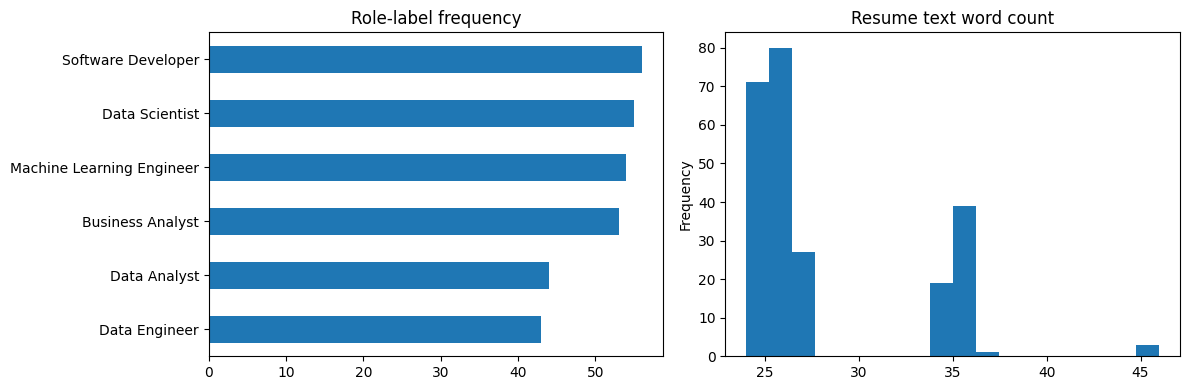

In [3]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
label_counts.sort_values().plot(kind="barh",ax=ax[0],title="Role-label frequency")
resumes.word_count.plot(kind="hist",bins=18,ax=ax[1],title="Resume text word count")
plt.tight_layout()
plt.show()


## 3. Encode multi-label targets

In [4]:
role_names=job_roles.role_name.tolist()
mlb=MultiLabelBinarizer(classes=role_names)
Y=mlb.fit_transform(resumes.labels_list)
print("Output role order:",list(mlb.classes_))
print("Target matrix shape:",Y.shape)
print("First five multi-hot target rows:\n",Y[:5])


Output role order: ['Data Analyst', 'Data Scientist', 'Machine Learning Engineer', 'Data Engineer', 'Software Developer', 'Business Analyst']
Target matrix shape: (240, 6)
First five multi-hot target rows:
 [[1 0 1 0 1 0]
 [0 1 0 0 0 0]
 [0 0 1 0 0 0]
 [0 0 0 1 0 0]
 [0 0 0 0 1 0]]


## 4. Split data and preprocess features (fit only on training data)

In [5]:
features=resumes[["resume_text","skills","education","experience_years"]]
X_train,X_test,y_train,y_test=train_test_split(features,Y,test_size=.20,random_state=42)
preprocessor=ColumnTransformer([
 ("resume_tfidf",TfidfVectorizer(max_features=3000,ngram_range=(1,2),stop_words="english"),"resume_text"),
 ("skill_tokens",TfidfVectorizer(token_pattern=r"[^;]+",binary=True),"skills"),
 ("experience",StandardScaler(with_mean=False),["experience_years"]),
 ("education",OneHotEncoder(handle_unknown="ignore"),["education"])
],sparse_threshold=1.0)
X_train_vec=preprocessor.fit_transform(X_train)
X_test_vec=preprocessor.transform(X_test)
print("Training matrix:",X_train_vec.shape," Test matrix:",X_test_vec.shape)


Training matrix: (192, 253)  Test matrix: (48, 253)


## 5. Build and train the ANN (MLP)

In [6]:
ann=MLPClassifier(hidden_layer_sizes=(128,64),activation="relu",solver="adam",
    alpha=1e-4,batch_size=16,learning_rate_init=.001,max_iter=160,
    early_stopping=True,validation_fraction=.15,n_iter_no_change=15,random_state=42)
ann.fit(X_train_vec,y_train)
print("Training iterations:",ann.n_iter_)
print("Final training loss:",round(float(ann.loss_),5))


Training iterations: 24
Final training loss: 0.01678


## 6. Evaluate multi-label recommendations

In [7]:
probabilities=ann.predict_proba(X_test_vec)
if isinstance(probabilities,list):
    probabilities=np.column_stack([p[:,1] if p.ndim==2 else p for p in probabilities])
predictions=(probabilities>=.50).astype(int)
metrics={
 "micro_precision":precision_score(y_test,predictions,average="micro",zero_division=0),
 "micro_recall":recall_score(y_test,predictions,average="micro",zero_division=0),
 "micro_f1":f1_score(y_test,predictions,average="micro",zero_division=0),
 "macro_f1":f1_score(y_test,predictions,average="macro",zero_division=0),
 "weighted_f1":f1_score(y_test,predictions,average="weighted",zero_division=0),
 "hamming_loss":hamming_loss(y_test,predictions),
 "sample_jaccard":jaccard_score(y_test,predictions,average="samples",zero_division=0),
 "subset_accuracy":float(np.mean(np.all(y_test==predictions,axis=1)))
}
display(pd.DataFrame({"metric":metrics.keys(),"value":np.round(list(metrics.values()),4)}))
print(classification_report(y_test,predictions,target_names=mlb.classes_,zero_division=0))


,metric,value
0,micro_precision,1.0000
1,micro_recall,0.9841
2,micro_f1,0.9920
3,macro_f1,0.9928
4,weighted_f1,0.9917
5,hamming_loss,0.0035
6,sample_jaccard,0.9792
7,subset_accuracy,0.9792


                           precision    recall  f1-score   support

             Data Analyst       1.00      0.92      0.96        12
           Data Scientist       1.00      1.00      1.00        11
Machine Learning Engineer       1.00      1.00      1.00         9
            Data Engineer       1.00      1.00      1.00        10
       Software Developer       1.00      1.00      1.00        11
         Business Analyst       1.00      1.00      1.00        10

                micro avg       1.00      0.98      0.99        63
                macro avg       1.00      0.99      0.99        63
             weighted avg       1.00      0.98      0.99        63
              samples avg       0.98      0.98      0.98        63



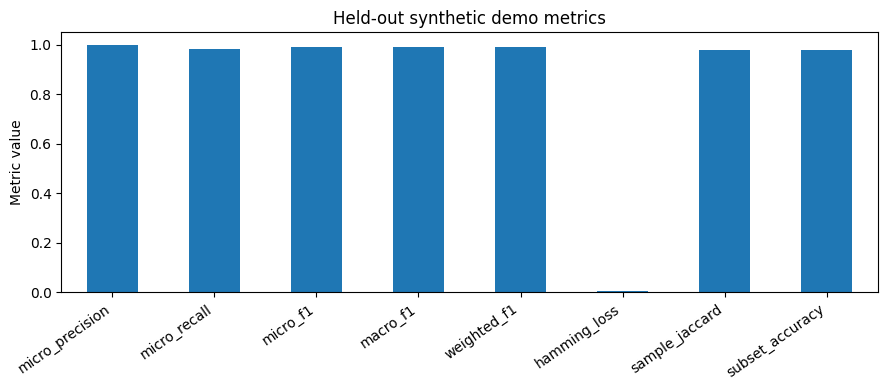

In [8]:
pd.Series(metrics).plot(kind="bar",figsize=(9,4),title="Held-out synthetic demo metrics")
plt.ylabel("Metric value"); plt.xticks(rotation=35,ha="right"); plt.tight_layout(); plt.show()


## 7. Save trained model and preprocessing artifacts

In [9]:
MODEL_DIR=ROOT/"models"; MODEL_DIR.mkdir(exist_ok=True)
joblib.dump(preprocessor,MODEL_DIR/"feature_preprocessor.joblib")
joblib.dump(ann,MODEL_DIR/"multilabel_mlp_demo.joblib")
joblib.dump(mlb,MODEL_DIR/"role_binarizer.joblib")
(MODEL_DIR/"role_names.json").write_text(json.dumps(list(mlb.classes_),indent=2))
(ROOT/"results/metrics/demo_metrics.json").write_text(json.dumps({k:float(v) for k,v in metrics.items()},indent=2))
print("Saved preprocessor, ANN model, role encoder and metrics.")


Saved preprocessor, ANN model, role encoder and metrics.


## 8. Create a reusable recommendation function

In [10]:
def recommend_roles(resume_text,skills,education="Bachelor",experience_years=0,threshold=.50,top_k=3):
    skills_text=";".join(skills) if isinstance(skills,(list,tuple,set)) else str(skills)
    candidate=pd.DataFrame([{"resume_text":resume_text,"skills":skills_text,
                              "education":education,"experience_years":float(experience_years)}])
    vec=preprocessor.transform(candidate)
    scores=ann.predict_proba(vec)
    if isinstance(scores,list): scores=np.column_stack([p[:,1] if p.ndim==2 else p for p in scores])
    ranked=sorted(zip(mlb.classes_,scores.reshape(-1)),key=lambda z:z[1],reverse=True)
    selected=[(r,float(s)) for r,s in ranked if s>=threshold]
    if not selected: selected=[(r,float(s)) for r,s in ranked[:top_k]]
    return pd.DataFrame(selected,columns=["recommended_role","model_score"])
display(recommend_roles("Python SQL dashboard reporting statistics and business insights",
 ["python","sql","power bi","excel","statistics"],"Bachelor",2,threshold=.35))


,recommended_role,model_score
0,Business Analyst,0.320517
1,Data Analyst,0.319558
2,Data Engineer,0.241697


# 9. Additional candidate recommendation snippets
Run these after training. Edit the text, skill list, education, experience and threshold to test different candidate profiles. Scores are model scores, not calibrated hiring probabilities.

In [11]:
# Example 1 — Data analytics profile
example_1=recommend_roles(
 "Created SQL reports, Excel dashboards, Power BI visualizations and statistical summaries.",
 ["sql","excel","power bi","tableau","statistics","data visualization"],"Bachelor",1,.30)
display(example_1)


,recommended_role,model_score
0,Data Analyst,0.540174
1,Business Analyst,0.367353
2,Machine Learning Engineer,0.322496


In [12]:
# Example 2 — Machine learning profile
example_2=recommend_roles(
 "Built Python ML models with TensorFlow, Keras, pandas and scikit-learn; deployed models with Docker.",
 ["python","machine learning","tensorflow","keras","scikit-learn","model deployment","docker"],"Master",3,.30)
display(example_2)


,recommended_role,model_score
0,Machine Learning Engineer,0.744801
1,Data Scientist,0.313153


In [13]:
# Example 3 — Data engineering profile
example_3=recommend_roles(
 "Developed ETL workflows and data pipelines using Python, SQL, Spark, Airflow and cloud services.",
 ["python","sql","etl","spark","airflow","data pipelines","cloud"],"Bachelor",4,.30)
display(example_3)


,recommended_role,model_score
0,Data Engineer,0.907849
1,Data Scientist,0.414258


In [14]:
# Example 4 — Software development profile
example_4=recommend_roles(
 "Built software applications and APIs using Java, Python, JavaScript, Git and testing.",
 ["java","python","javascript","git","api development","data structures","testing"],"Bachelor",2,.30)
display(example_4)


,recommended_role,model_score
0,Software Developer,0.945122


In [15]:
# Example 5 — Business analysis profile with a stricter threshold
example_5=recommend_roles(
 "Gathered business requirements, communicated with stakeholders, and created SQL, Excel and Power BI reports.",
 ["requirements gathering","stakeholder communication","sql","excel","power bi","business analysis"],"Master",5,.65,top_k=4)
display(example_5)


,recommended_role,model_score
0,Business Analyst,0.798135


## 10. Skill-gap analysis (separate from ANN prediction)

In [16]:
def skill_gap(candidate_skills,role_name):
    row=job_roles.loc[job_roles.role_name==role_name]
    if row.empty: raise ValueError("Unknown role: "+role_name)
    required=set(split_labels(row.iloc[0].required_skills))
    present={str(s).strip().lower() for s in candidate_skills}
    matched=sorted(required & present); missing=sorted(required-present)
    return {"role":role_name,"matched_skills":matched,"missing_skills":missing,
            "coverage":round(len(matched)/len(required),3) if required else 0}
display(skill_gap(["python","sql","excel","power bi"],"Data Analyst"))


{'role': 'Data Analyst',
 'matched_skills': ['excel', 'power bi', 'python', 'sql'],
 'missing_skills': ['data visualization', 'statistics', 'tableau'],
 'coverage': 0.571}

## 11. How the ANN works — explanation

1. **TF-IDF:** converts words and phrases into weighted numeric features. Terms that are informative in a resume receive greater weight than terms common across all resumes.
2. **Structured data:** skills are tokenized as a binary feature block; experience is scaled; education is one-hot encoded.
3. **Input layer:** receives the concatenated numerical representation of each resume.
4. **Hidden layers:** the MLP uses dense layers with ReLU activation to learn nonlinear combinations of terms and profile information.
5. **Output layer:** one sigmoid/logistic output corresponds to each role. Multiple outputs can be high at the same time, which is why this is multi-label classification. Softmax would incorrectly force the roles to compete as if only one were correct.
6. **Training:** the network compares each role score with the corresponding 0/1 target and updates weights using backpropagation and Adam.
7. **Inference:** roles are ranked by score; a configurable threshold selects multiple recommendations.

### Important limitations
The included labels are synthetic and template-derived. Real performance requires a suitably licensed public dataset with trustworthy multi-label annotations, a careful split that prevents duplicate/person leakage, validation-based threshold tuning, and independent testing. Recommendations are educational guidance, not hiring decisions or guaranteed employment outcomes.